# Aviation Accidents Analysis

You are part of a consulting firm that is tasked to do an analysis of commercial and passenger jet airline safety. The client (an airline/airplane insurer) is interested in knowing what types of aircraft (makes/models) exhibit low rates of total destruction and low likelihood of fatal or serious passenger injuries in the event of an accident. They are also interested in any general variables/conditions that might be at play. Your analysis will be based off of aviation accident data accumulated from the years 1948-2023. 

Our client is only interested in airplane makes/models that are professional builds and could potentially still be active. Assume a max lifetime of 40 years for a make/model retirement and make sure to filter your data accordingly (i.e. from 1983 onwards). They would also like separate recommendations for small aircraft vs. larger passenger models. **In addition, make sure that claims that you make are statistically robust and that you have enough samples when making comparisons between groups.**


In this summative assessment you will demonstrate your ability to:
- Use Pandas to load, inspect, and clean the dataset appropriately. 
- Transform relevant columns to create measures that address the problem at hand.
- **conduct EDA: visualization and statistical measures to understand the structure of the data**
- **recommend a set of manufacturers to consider as well as specific airplanes conforming to the client's request**
- **discuss the relationship between serious injuries/airplane damage incurred and at least *two* factors at play in the incident. You must provide supporting evidence (visuals, summary statistics, tables) for each claim you make.**

In [1]:
# loading relevant packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Exploratory Data Analysis  
- Load in the cleaned data

In [2]:
df = pd.read_csv("data/cleaned_aviation_data.csv")
df["Event.Date"] = pd.to_datetime(df["Event.Date"])
print(df.shape)
df.head()

(55090, 29)


,Event.Id,Investigation.Type,Accident.Number,Event.Date,Location,Country,Injury.Severity,Aircraft.damage,Aircraft.Category,Registration.Number,...,Total.Uninjured,Weather.Condition,Broad.phase.of.flight,Report.Status,Total.Occupants,FatalSerious.Count,FatalSerious.Rate,FatalSerious.Any,Destroyed,Make.Model
0,20001214X42095,Accident,SEA83LA036,1983-01-01,"NEWPORT, OR",United States,Non-Fatal,Substantial,Airplane,N1296M,...,3.0,VMC,Approach,Probable Cause,4.0,0.0,0.0,0,0,CESSNA 182P
1,20001214X42067,Accident,MKC83LA056,1983-01-01,"WOODBINE, IA",United States,Non-Fatal,Substantial,Airplane,N2639C,...,2.0,VMC,Landing,Probable Cause,2.0,0.0,0.0,0,0,CESSNA 182RG
2,20001214X42063,Accident,MKC83LA050,1983-01-01,"MARYVILLE, MO",United States,Non-Fatal,Substantial,Airplane,N58664,...,1.0,VMC,Takeoff,Probable Cause,1.0,0.0,0.0,0,0,CESSNA 182P
3,20001214X42018,Accident,LAX83FUG11,1983-01-01,"UPLAND, CA",United States,Non-Fatal,Substantial,Airplane,N3084R,...,0.0,VMC,Approach,Probable Cause,2.0,0.0,0.0,0,0,PIPER PA-28R-200
4,20001214X41951,Accident,CHI83LA074,1983-01-01,"SPRINGBROOK, WI",United States,Non-Fatal,Substantial,Airplane,N89399,...,2.0,VMC,Landing,Probable Cause,2.0,0.0,0.0,0,0,CESSNA 140


## Explore safety metrics across models/makes
- Remember that the client is interested in separate recommendations for smaller airplanes and larger airplanes. Choose a passenger threshold of 20 and separate the plane types. 

In [3]:
#Largest number of occupants ever recorded for each plane type
max_occ = df.groupby("Make.Model")["Total.Occupants"].max()

# Large = plane type has had an accident with 20+ occupants
large_types = max_occ[max_occ >= 20].index
df["Size"] = np.where(df["Make.Model"].isin(large_types), "Large", "Small")

print(df["Size"].value_counts())
print(df.groupby("Size")["Make.Model"].nunique())

Size
Small    52311
Large     2779
Name: count, dtype: int64
Size
Large     248
Small    1990
Name: Make.Model, dtype: int64


In [4]:
for t in ["CESSNA 172", "BOEING 737-200", "BOEING 747-100"]:
    print(t, df.loc[df["Make.Model"] == t, "Size"].unique())

CESSNA 172 <StringArray>
['Small']
Length: 1, dtype: str
BOEING 737-200 <StringArray>
['Large']
Length: 1, dtype: str
BOEING 747-100 <StringArray>
[]
Length: 0, dtype: str


#### Analyzing Makes

Explore the human injury risk profile for small and larger Makes:
- choose the 15 makes for each group possessing the lowest mean fatal/seriously injured fraction
- plot the mean fatal/seriously injured fraction for each of these subgroups side-by-side

Small makes meeting threshold: 15
                                accidents  fatal_serious_rate  destroyed_rate
Make                                                                         
GRUMMAN-SCHWEIZER                     118               0.103           0.220
WACO                                   98               0.131           0.102
GREAT LAKES                            53               0.142           0.113
SCHWEIZER                             120               0.150           0.225
MAULE                                 495               0.162           0.093
HELIO                                  69               0.166           0.159
AVIAT AIRCRAFT INC                     75               0.167           0.040
BOEING                                355               0.175           0.124
WEATHERLY                              75               0.200           0.213
AVIAT                                 134               0.201           0.075
WSK PZL MIELEC                

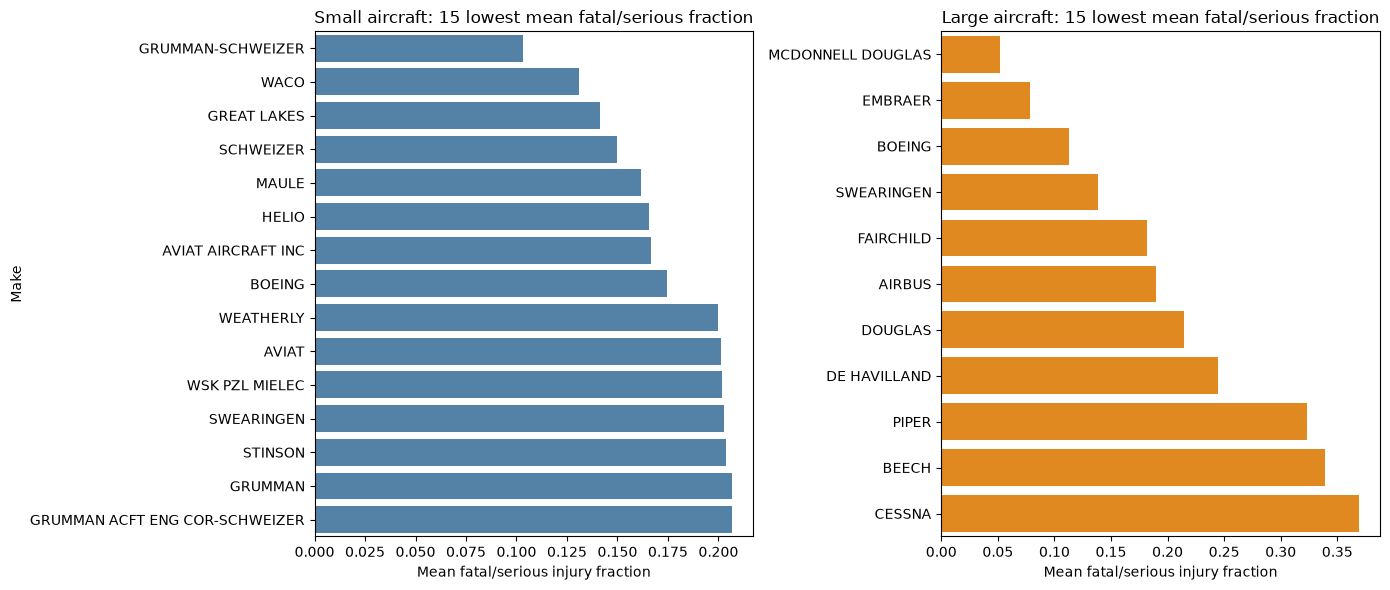

In [5]:
MIN_N = 30   # minimum accidents per make for a reliable mean

def safest_makes(size, min_n, top=15):
    sub = df[df["Size"] == size]
    g = (sub.groupby("Make")
            .agg(accidents=("Event.Id", "count"),
                 fatal_serious_rate=("FatalSerious.Rate", "mean"),
                 destroyed_rate=("Destroyed", "mean"))
            .query("accidents >= @min_n")
            .sort_values("fatal_serious_rate")
            .head(top))
    return g

small_top = safest_makes("Small", MIN_N)
large_top = safest_makes("Large", MIN_N)

print("Small makes meeting threshold:", len(small_top))
print(small_top.round(3))
print("-----")
print("Large makes meeting threshold:", len(large_top))
print(large_top.round(3))

# Side-by-side plot
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
sns.barplot(x=small_top["fatal_serious_rate"], y=small_top.index, ax=axes[0], color="steelblue")
axes[0].set_title("Small aircraft: 15 lowest mean fatal/serious fraction")
axes[0].set_xlabel("Mean fatal/serious injury fraction")
axes[0].set_ylabel("Make")

sns.barplot(x=large_top["fatal_serious_rate"], y=large_top.index, ax=axes[1], color="darkorange")
axes[1].set_title("Large aircraft: 15 lowest mean fatal/serious fraction")
axes[1].set_xlabel("Mean fatal/serious injury fraction")
axes[1].set_ylabel("")
plt.tight_layout()
plt.show()

in small aircraft sector some have the lowest and mean fatal includes;Grummman-schweizer,Waco,Great lakes schweizer and Maule with each at least 50 accidents
in the large sector only embraer,booeing and airbus are lowest
only 11 large makes had at least 30 accidents
Cessna,piper and beech appear in the large group because their model carried more than 20 occupants but they are not reccommended as large aircraft


**Distribution of injury rates: small makes**

Use a violinplot to look at the distribution of the fraction of passengers serious/fatally injured for small airplane makes. Just display makes with the ten lowest mean serious/fatal injury rates.

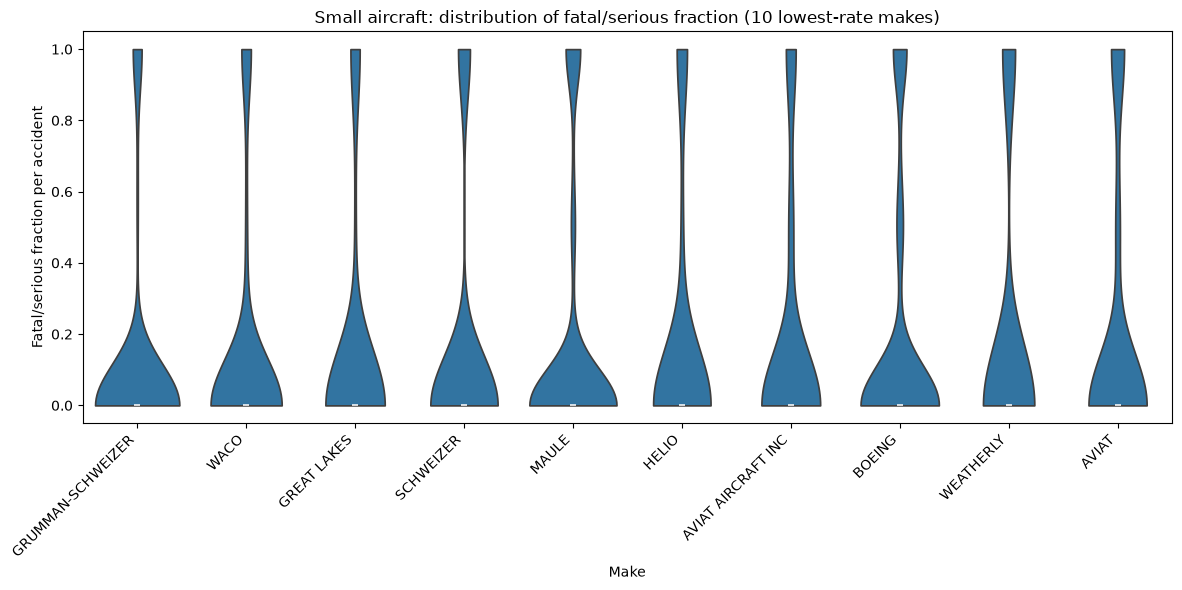

In [6]:
top10_small = small_top.index[:10]
sub = df[(df["Size"] == "Small") & (df["Make"].isin(top10_small))]

plt.figure(figsize=(12, 6))
sns.violinplot(data=sub, x="Make", y="FatalSerious.Rate", order=top10_small, cut=0)
plt.xticks(rotation=45, ha="right")
plt.title("Small aircraft: distribution of fatal/serious fraction (10 lowest-rate makes)")
plt.ylabel("Fatal/serious fraction per accident")
plt.tight_layout()
plt.show()

distribution is heavily concentrated at 0,means most accidents caused no fatal injury because small aircraft carries few occupants so the mean is driven by how often  the worst case occurs

**Distribution of injury rates: large makes**

Use a stripplot to look at the distribution of the fraction of passengers serious/fatally injured for large airplane makes. Just display makes with the ten lowest mean serious/fatal injury rates.

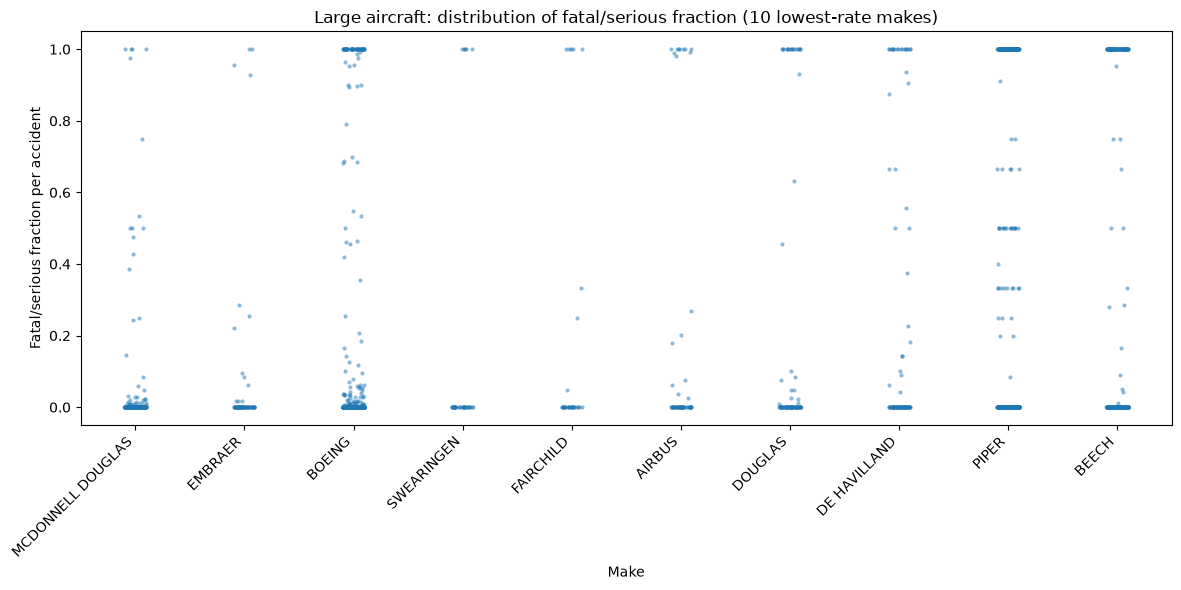

In [7]:
top10_large = large_top.index[:10]
sub = df[(df["Size"] == "Large") & (df["Make"].isin(top10_large))]

plt.figure(figsize=(12, 6))
sns.stripplot(data=sub, x="Make", y="FatalSerious.Rate", order=top10_large,
              jitter=True, alpha=0.5, size=3)
plt.xticks(rotation=45, ha="right")
plt.title("Large aircraft: distribution of fatal/serious fraction (10 lowest-rate makes)")
plt.ylabel("Fatal/serious fraction per accident")
plt.tight_layout()
plt.savefig("The images/makes_injury.png",dpi=150,bbox_inches="tight")
plt.show()

for the ten lowest -rate large makes most accidents sit at serious fraction of 0

**Evaluate the rate of aircraft destruction for both small and large aircraft by Make.** 

Sort your results and keep the lowest 15.

Small aircraft: 15 lowest destroyed rates
                                accidents  destroyed_rate  fatal_serious_rate
Make                                                                         
GRUMMAN ACFT ENG COR-SCHWEIZER         58           0.017               0.207
AMERICAN CHAMPION AIRCRAFT             53           0.038               0.283
AVIAT AIRCRAFT INC                     75           0.040               0.167
DIAMOND AIRCRAFT IND INC               74           0.054               0.223
FLIGHT DESIGN GMBH                     50           0.060               0.370
AVIAT                                 134           0.075               0.201
MAULE                                 495           0.093               0.162
ERCOUPE                                72           0.097               0.350
LUSCOMBE                              364           0.102               0.228
WACO                                   98           0.102               0.131
FAIRCHILD             

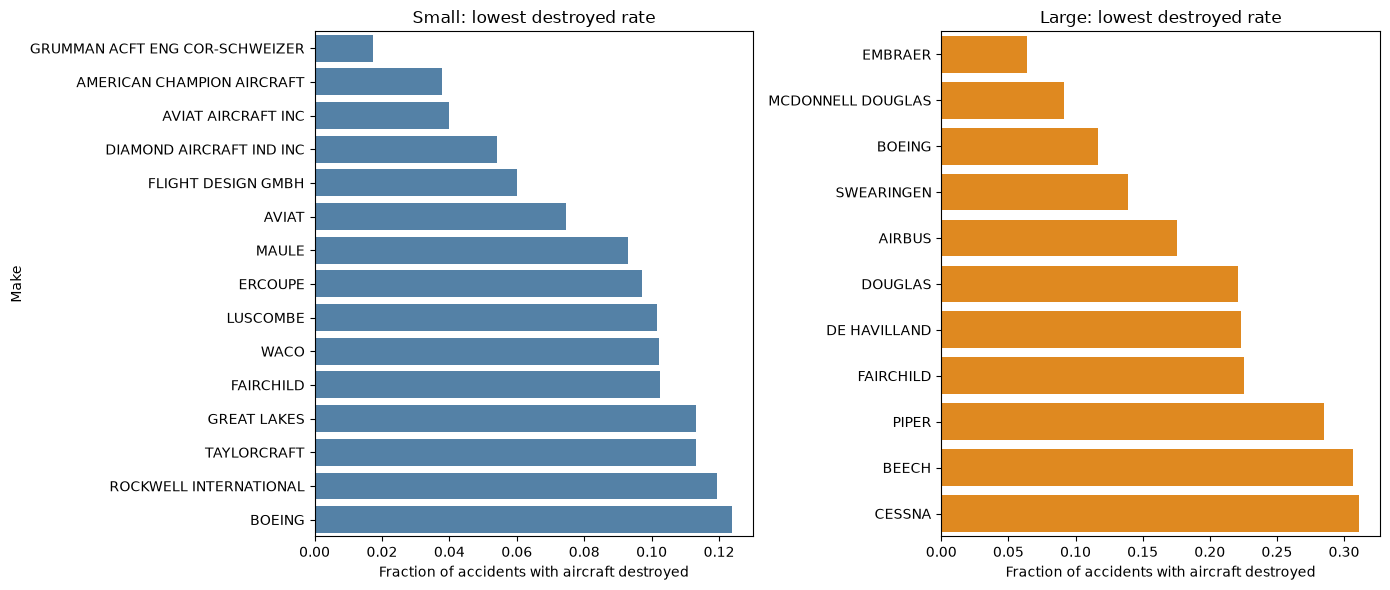

In [8]:
def lowest_destroyed(size, min_n=30, top=15):
    sub = df[df["Size"] == size]
    return (sub.groupby("Make")
               .agg(accidents=("Event.Id", "count"),
                    destroyed_rate=("Destroyed", "mean"),
                    fatal_serious_rate=("FatalSerious.Rate", "mean"))
               .query("accidents >= @min_n")
               .sort_values("destroyed_rate")
               .head(top))

small_destroyed = lowest_destroyed("Small")
large_destroyed = lowest_destroyed("Large")

print("Small aircraft: 15 lowest destroyed rates")
print(small_destroyed.round(3))
print("-----")
print("Large aircraft: 15 lowest destroyed rates")
print(large_destroyed.round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
sns.barplot(x=small_destroyed["destroyed_rate"], y=small_destroyed.index, ax=axes[0], color="steelblue")
axes[0].set_title("Small: lowest destroyed rate")
axes[0].set_xlabel("Fraction of accidents with aircraft destroyed")
sns.barplot(x=large_destroyed["destroyed_rate"], y=large_destroyed.index, ax=axes[1], color="darkorange")
axes[1].set_title("Large: lowest destroyed rate")
axes[1].set_xlabel("Fraction of accidents with aircraft destroyed")
axes[1].set_ylabel("")
plt.tight_layout()
plt.savefig("The images/makes_destroyed.png",dpi=150,bbox_inches="tight")
plt.show()

#### Provide a short discussion on your findings for your summary statistics and plots:
- Make any recommendations for Makes here based off of the destroyed fraction and fraction fatally/seriously injured
- Comment on the calculated statistics and any corresponding distributions you have visualized.

Large aircraft: Embraer, McDonnell Douglas and Boeing are the strongest choices. Embraer has the lowest destroyed rate (0.06) and a low fatal/serious fraction (0.08). McDonnell Douglas has the lowest fatal/serious fraction (0.05) and a low destroyed rate (0.09). Boeing has the largest sample (650 accidents), with a destroyed rate of 0.12 and a fatal/serious fraction of 0.11, so its numbers are the most reliable. Airbus (0.18 and 0.19) is acceptable but weaker. Cessna, Piper and Beech appear in the large group only because some of their models carried 20 or more occupants, and their high rates reflect many small aircraft, so they are not recommended as large aircraft. Swearingen and Fairchild have fewer than 40 accidents, so their rates are less reliable.

Small aircraft: Maule, Waco and Great Lakes are the best on both measures, with destroyed rates of 0.08 to 0.11 and fatal/serious fractions of 0.13 to 0.16. Maule has the largest sample (495 accidents), so it is the most dependable recommendation. Some makes, such as Ercoupe, Luscombe and Taylorcraft, rarely have the aircraft destroyed but have high fatal/serious fractions (0.30 to 0.37), so a low destroyed rate alone is not enough.

Distributions: In the violin and strip plots, most accidents have a fatal/serious fraction of 0 and a smaller number are near 1.0. Differences between makes come from how often the worst-case accidents happen, not from a different shape of distribution. Small aircraft carry few occupants, so their fractions cluster at 0, 0.5 and 1. All rates are based on makes with at least 30 accidents, but makes near that minimum have wider uncertainty.

### Analyze plane types
- plot the mean fatal/seriously injured fraction for both small and larger planes 
- also provide a distributional plot of your choice for the fatal/seriously injured fraction by airplane type (stripplot, violin, etc)  
- filter ensuring that you have at least ten individual examples in each model/make to average over

**Larger planes**

Large plane types with at least 10 accidents: 55
                            accidents  fatal_serious_rate  destroyed_rate
Make.Model                                                               
BOEING 757-232                     10               0.000           0.000
BOEING 777                         24               0.000           0.042
BOEING 757-222                     10               0.000           0.000
MCDONNELL DOUGLAS MD-11F           10               0.000           0.100
MCDONNELL DOUGLAS MD-83            13               0.001           0.077
MCDONNELL DOUGLAS MD-80            11               0.001           0.000
MCDONNELL DOUGLAS MD-88            17               0.003           0.000
MCDONNELL DOUGLAS DC-9-51          11               0.006           0.091
MCDONNELL DOUGLAS DC-10-10         19               0.029           0.053
BOEING 727-200                     24               0.044           0.042
BOEING 747-400                     13               0.052      

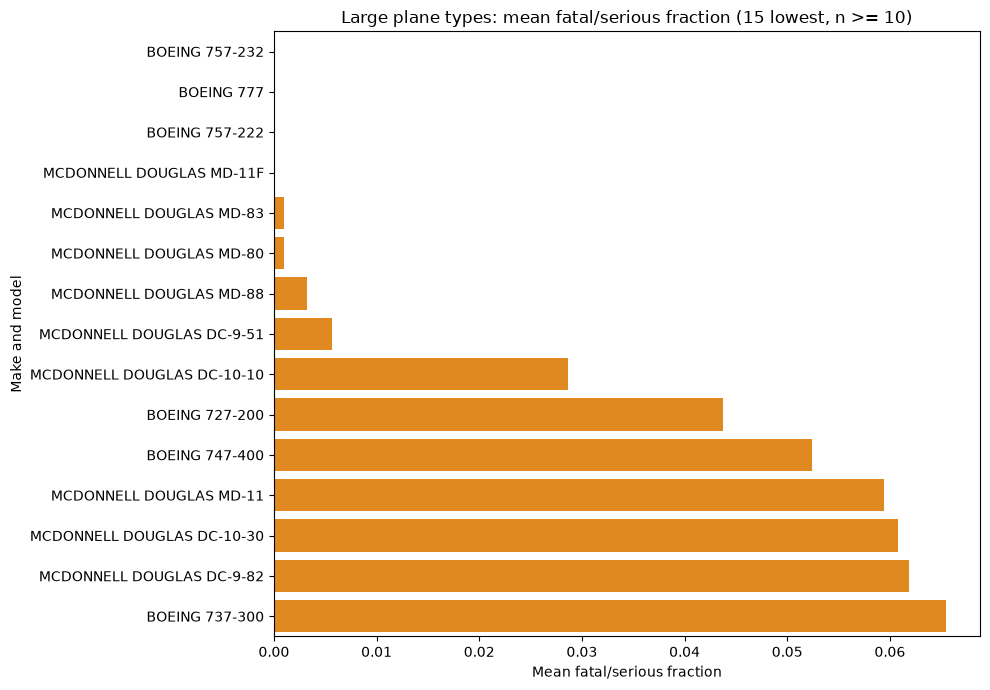

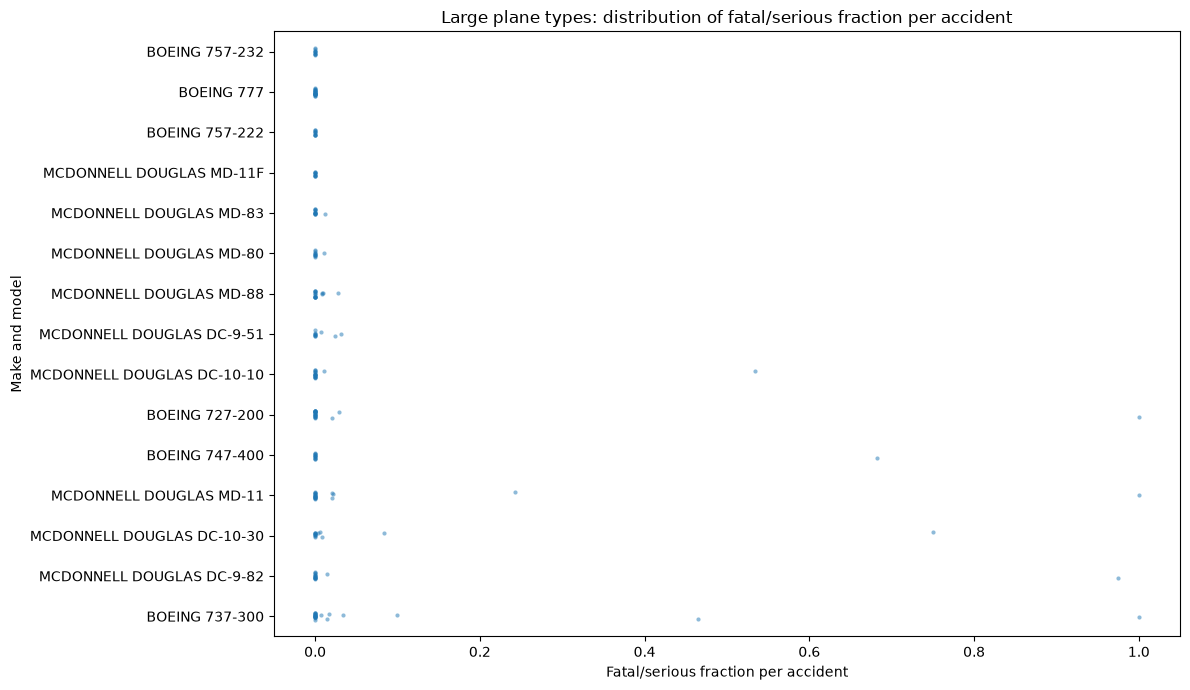

In [9]:
MIN_TYPE_N = 10

large_df = df[df["Size"] == "Large"]
large_types = (large_df.groupby("Make.Model")
                .agg(accidents=("Event.Id", "count"),
                     fatal_serious_rate=("FatalSerious.Rate", "mean"),
                     destroyed_rate=("Destroyed", "mean"))
                .query("accidents >= @MIN_TYPE_N")
                .sort_values("fatal_serious_rate"))

print("Large plane types with at least 10 accidents:", len(large_types))
print(large_types.head(15).round(3))

# Bar plot of mean fraction for the 15 lowest
top_large = large_types.head(15)
plt.figure(figsize=(10, 7))
sns.barplot(x=top_large["fatal_serious_rate"], y=top_large.index, color="darkorange")
plt.title("Large plane types: mean fatal/serious fraction (15 lowest, n >= 10)")
plt.xlabel("Mean fatal/serious fraction")
plt.ylabel("Make and model")
plt.tight_layout()
plt.show()

# Distribution plot for the same types
sub = large_df[large_df["Make.Model"].isin(top_large.index)]
plt.figure(figsize=(12, 7))
sns.stripplot(data=sub, x="FatalSerious.Rate", y="Make.Model",
              order=top_large.index, jitter=True, alpha=0.5, size=3)
plt.title("Large plane types: distribution of fatal/serious fraction per accident")
plt.xlabel("Fatal/serious fraction per accident")
plt.ylabel("Make and model")
plt.tight_layout()
plt.show()

**Smaller planes**
- for smaller planes, limit your plotted results to the makes with the 10 lowest mean serious/fatal injury fractions

Small plane types with at least 10 accidents: 681
                                   accidents  fatal_serious_rate  \
Make.Model                                                         
PIPER PA-18A 150                          12               0.000   
AYRES S2R-G10                             12               0.000   
DIAMOND AIRCRAFT IND INC DA 20 C1         11               0.000   
GRUMMAN G164B                             16               0.000   
CESSNA 180C                               15               0.000   
MAULE MX-7-235                            17               0.029   
GRUMMAN-SCHWEIZER G-164A                  49               0.034   
CESSNA C172                               12               0.042   
NORTH AMERICAN AT-6G                      11               0.045   
PIPER PA-18-160                           31               0.048   

                                   destroyed_rate  
Make.Model                                         
PIPER PA-18A 150             

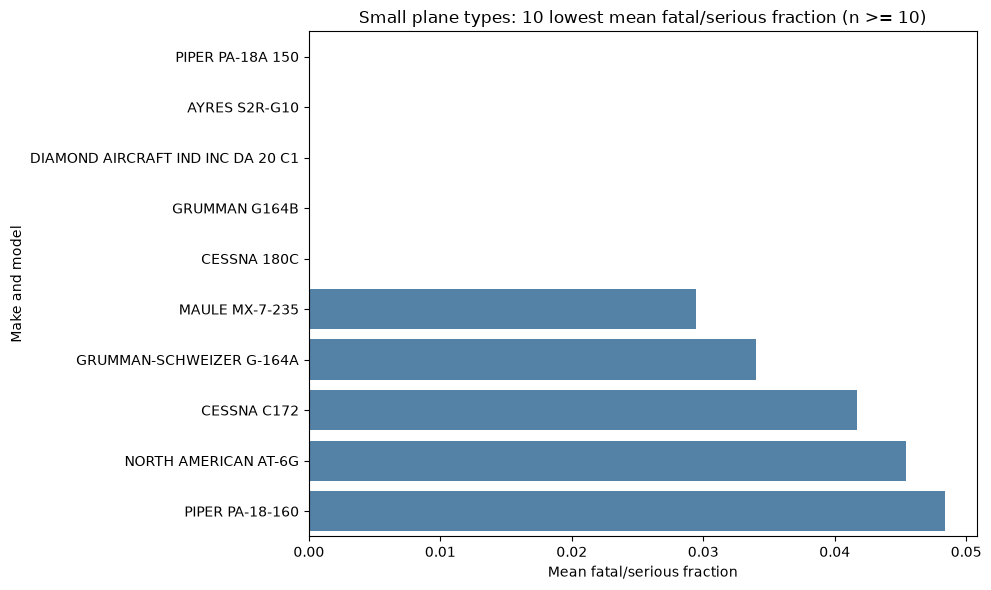

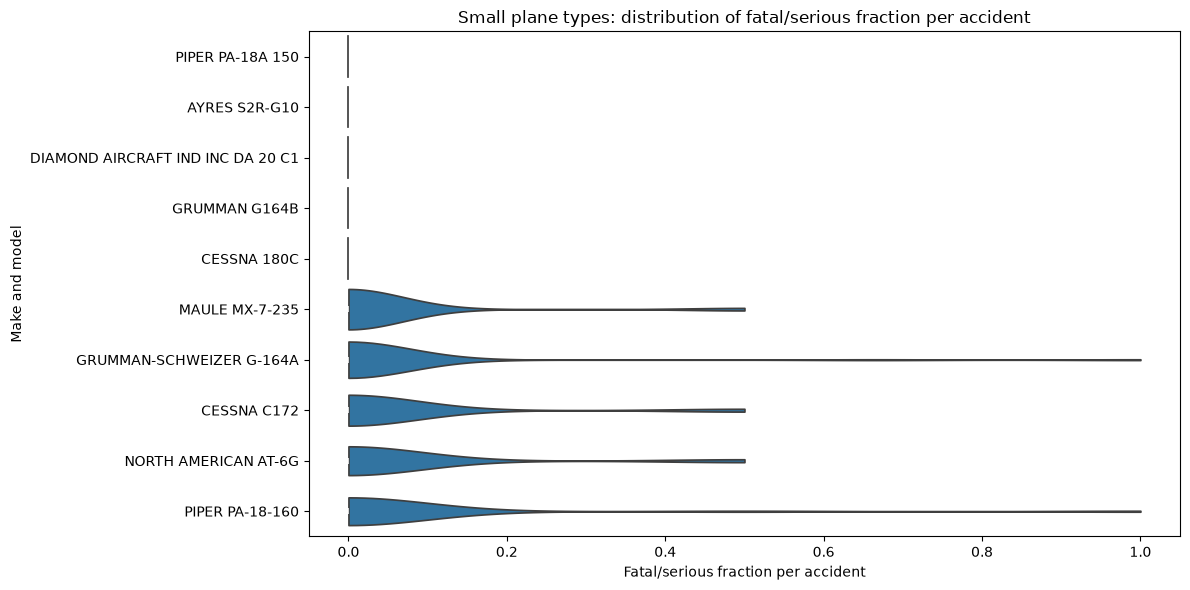

In [10]:
small_df = df[df["Size"] == "Small"]
small_types = (small_df.groupby("Make.Model")
                .agg(accidents=("Event.Id", "count"),
                     fatal_serious_rate=("FatalSerious.Rate", "mean"),
                     destroyed_rate=("Destroyed", "mean"))
                .query("accidents >= @MIN_TYPE_N")
                .sort_values("fatal_serious_rate"))

top_small = small_types.head(10)
print("Small plane types with at least 10 accidents:", len(small_types))
print(top_small.round(3))

plt.figure(figsize=(10, 6))
sns.barplot(x=top_small["fatal_serious_rate"], y=top_small.index, color="steelblue")
plt.title("Small plane types: 10 lowest mean fatal/serious fraction (n >= 10)")
plt.xlabel("Mean fatal/serious fraction")
plt.ylabel("Make and model")
plt.tight_layout()
plt.show()

sub = small_df[small_df["Make.Model"].isin(top_small.index)]
plt.figure(figsize=(12, 6))
sns.violinplot(data=sub, x="FatalSerious.Rate", y="Make.Model",
               order=top_small.index, cut=0, orient="h")
plt.title("Small plane types: distribution of fatal/serious fraction per accident")
plt.xlabel("Fatal/serious fraction per accident")
plt.ylabel("Make and model")
plt.tight_layout()
plt.show()

### Discussion of Specific Airplane Types
- Discuss what you have found above regarding passenger fraction seriously/ both small and large airplane models.

Large planes:of the 55 large plane types with at least 10 accidents, the 15 with the lowest mean fatal/serious fraction are almost all Boeing and McDonnell Douglas models, with means below 0.07. Boeing 757-232, 757-222 and 777 and McDonnell Douglas MD-11F, MD-83 and MD-80 have means at or near 0. Their distributions are concentrated at 0, with only a few accidents causing partial injuries. Because some of these models have only 10 to 13 accidents, a mean of 0 is promising but not conclusive. The most reliable large-aircraft recommendations are those with larger samples: Boeing 777 (24 accidents, fatal/serious 0.00, destroyed 0.04) and Boeing 737-300 (25 accidents, 0.07 and 0.12).

Small plane:Of the 681 small plane types with at least 10 accidents, the lowest fatal/serious fractions belong to Piper PA-18A 150, Ayres S2R-G10, Diamond DA 20 C1, Grumman G164B and Cessna 180C (all 0.00, with 11 to 16 accidents). The violin plots show these as a single flat line at 0, but their samples are small. Maule MX-7-235 (49 accidents, 0.03), Piper PA-18-160 (31 accidents, 0.05) and Grumman-Schweizer G-164A (17 accidents, 0.03) have larger samples and similar low means, so they are more dependable picks. For these models, the distribution has a large mass at 0 and a thin tail, meaning severe accidents are rare but possible.

Overall: Models from the makes recommended earlier (Boeing, McDonnell Douglas, Embraer for large aircraft; Maule, Waco, Great Lakes for small aircraft) are supported by the model-level results. Model-level averages rest on far fewer accidents than make-level averages, so make-level results should carry more weight in the final recommendation.

### Exploring Other Variables
- Investigate how other variables effect aircraft damage and injury. You must choose **two** factors out of the following but are free to analyze more:

- Weather Condition
- Engine Type
- Number of Engines
- Phase of Flight
- Purpose of Flight

For each factor provide a discussion explaining your analysis with appropriate visualization / data summaries and interpreting your findings.

                       accidents  fatal_serious_rate  destroyed_rate
Broad.phase.of.flight                                               
Taxi                        1314               0.016           0.021
Landing                    11059               0.035           0.042
Standing                     433               0.089           0.125
Takeoff                     8158               0.225           0.214
Go-around                   1097               0.296           0.283
Descent                     1157               0.342           0.326
Approach                    4164               0.349           0.296
Cruise                      6567               0.351           0.340
Other                         52               0.382           0.308
Climb                       1272               0.430           0.430
Maneuvering                 4230               0.525           0.467


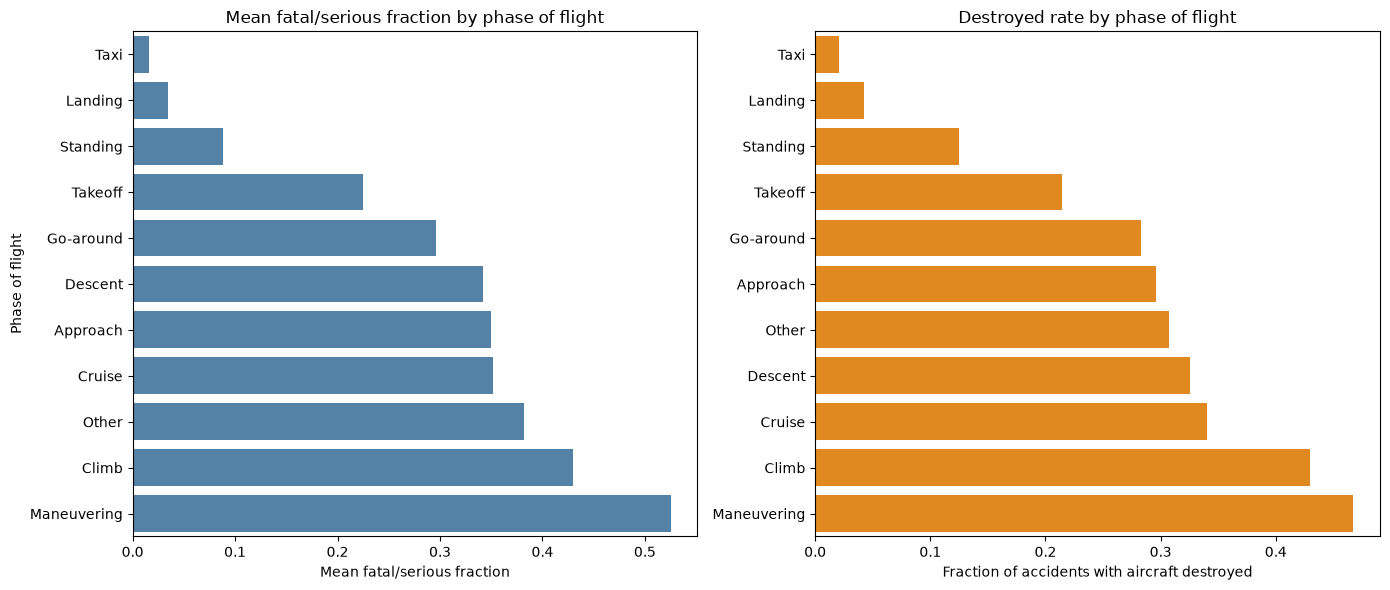

In [11]:
phase = (df.dropna(subset=["Broad.phase.of.flight"])
           .groupby("Broad.phase.of.flight")
           .agg(accidents=("Event.Id", "count"),
                fatal_serious_rate=("FatalSerious.Rate", "mean"),
                destroyed_rate=("Destroyed", "mean"))
           .query("accidents >= 30")
           .sort_values("fatal_serious_rate"))
print(phase.round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
sns.barplot(x=phase["fatal_serious_rate"], y=phase.index, ax=axes[0], color="steelblue")
axes[0].set_title("Mean fatal/serious fraction by phase of flight")
axes[0].set_xlabel("Mean fatal/serious fraction")
axes[0].set_ylabel("Phase of flight")
phase_d = phase.sort_values("destroyed_rate")
sns.barplot(x=phase_d["destroyed_rate"], y=phase_d.index, ax=axes[1], color="darkorange")
axes[1].set_title("Destroyed rate by phase of flight")
axes[1].set_xlabel("Fraction of accidents with aircraft destroyed")
axes[1].set_ylabel("")
plt.tight_layout()
plt.show()

Analysis on phase of flight:
about 70% of Accident was recorded while those fewer than 30 was excluded.the landing and takeoff has the m,ost accidents
the most severe cases involves manouvering
accidents that happen in a phase are always from how dangerous they are

In [12]:
engine = df.dropna(subset=["Engine.Type"])

# Overall
overall = (engine.groupby("Engine.Type")
              .agg(accidents=("Event.Id", "count"),
                   fatal_serious_rate=("FatalSerious.Rate", "mean"),
                   destroyed_rate=("Destroyed", "mean"))
              .query("accidents >= 30")
              .sort_values("fatal_serious_rate"))
print(overall.round(3))

# Split by size so engine type isn't confused with aircraft size
by_size = (engine.groupby(["Size", "Engine.Type"])
              .agg(accidents=("Event.Id", "count"),
                   fatal_serious_rate=("FatalSerious.Rate", "mean"),
                   destroyed_rate=("Destroyed", "mean"))
              .query("accidents >= 30"))
print(by_size.round(3))

plot_df = engine[engine.groupby(["Size", "Engine.Type"])["Event.Id"].transform("count") >= 30]


               accidents  fatal_serious_rate  destroyed_rate
Engine.Type                                                 
Turbo Fan            780               0.113           0.113
Turbo Jet            188               0.231           0.213
Reciprocating      48799               0.257           0.198
Turbo Prop          2132               0.319           0.262
                     accidents  fatal_serious_rate  destroyed_rate
Size  Engine.Type                                                 
Large Reciprocating       1347               0.330           0.289
      Turbo Fan            531               0.067           0.072
      Turbo Jet             96               0.064           0.073
      Turbo Prop           296               0.240           0.236
Small Reciprocating      47452               0.255           0.196
      Turbo Fan            249               0.212           0.201
      Turbo Jet             92               0.404           0.359
      Turbo Prop          1836 

engine type was also recorded for approximately 94% of accidents ,groups fewer than 30 was excluded
engine type is closely linked to aircraft size so the results are showed differently

Engine type was recorded for about 94% of accidents, and groups with fewer than 30 accidents eg Geared Turbofan and Turbo Shaft was excluded. Engine type is closely linked to aircraft size, so results are shown separately for small and large aircraft.

 large aircraft such as Turbo Fan recorded 531 accidents and Turbo Jet 96 are considered to be the safest, with a mean fatal fraction of almost 0.07 and a destroyed rate of about 0.07.

Among the small aircraft:Reciprocating engines recorded 47,452 accidents and has a serious fraction of 0.26 and a destroyed rate of 0.20. Turbo Prop recorded1,836 accidents which is worse at 0.33 and 0.27. Small Turbo Jet 92 accidents at 0.40 and 0.36, but its sample is small.
in general turbofan and turbojet aircraft show the lowest injury and destruction risk, and turboprops show higher risk than reciprocating engines in small aircraft. Part of this difference reflects the aircraft they power rather than the engine alone. For an insurer, Turbo Fan aircraft carry the lowest risk, and about 6% of accidents with no recorded engine type were excluded.